# Lab L2-2：U-Net 告訴我瑕疵在哪、有多大（D2-2）

**需求單 #D2-2**（虛構公司：曜嶼電子，製造品保部維修站）：不只要知道「這片有問題」，還要每個瑕疵的**位置與面積**。
影像用公開資料集 **VisA 的 PCB1**（CC BY 4.0，Amazon spot-diff 倉庫）。

| 步驟 | 做什麼 | 輸出 |
|---|---|---|
| 1 | 讀資料：良品＋**少量**真實遮罩（技術員標的 50 張）用來訓練；另外 50 張真實不良品**只用來測試** | 張數 |
| 2 | 合成瑕疵（DRAEM 想法）：把別片板子的一小塊貼到良品上；看一個批次長什麼樣 | 條帶圖、批次網格 |
| 3 | U-Net（三層）：每一塊的 shape | shape 表 |
| 4 | 訓練：BCE ＋ Dice | loss 曲線 |
| 5 | 在**真實遮罩**上量 IoU、Dice；面積換算 mm² | 疊圖、IoU／Dice |
| 6 | Gradio：上傳 → 遮罩疊圖＋面積 | 網頁 |

> 2026-11-26 改版：第一版**只用合成瑕疵**訓練，T4 實跑在真實瑕疵上 IoU 全部是 0（合成的彩色斑塊和真的彎針、刮痕差太多）。
> 這一版加入 50 張真實遮罩（40 訓練、10 驗證，`K_REAL`），測試只用另外 50 張。改版後 T4 實跑（2026-11-26）：真實 IoU 0.304、Dice 0.411（見 `research/lab-runs.md`）。

In [1]:
# 第 1 格：環境
%pip install -q -U gradio
import torch, os, glob, random, platform, time
import numpy as np
print("torch", torch.__version__, "| python", platform.python_version())
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), f"| 可用 VRAM {free/1e9:.1f} / {total/1e9:.1f} GB")
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
SIZE = 256          # 沒有 GPU：改成 64
EPOCHS = 20         # 沒有 GPU：改成 2

torch 2.14.1+cu130 | python 3.13.16
GPU: Tesla T4 | 可用 VRAM 15.5 / 15.6 GB


## 1. 資料：VisA PCB1（和 D2-1 同一份）
解壓後的結構：`pcb1/Data/Images/Normal`、`pcb1/Data/Images/Anomaly`、`pcb1/Data/Masks/Anomaly`（遮罩和不良品同檔名，副檔名 .png）。
已經有 D2-1 的資料夾就不用再下載；講師若放在雲端硬碟，改 `PCB1_DIR`。

In [2]:
VISA_URL = "https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar"  # 約 1.9 GB（2026-11-24 確認）
PCB1_DIR = "data/download/visa/pcb1"

if not os.path.isdir(PCB1_DIR):
    os.makedirs("data/download/visa", exist_ok=True)
    if not os.path.exists("data/download/visa/VisA.tar"):
        os.system(f"wget -q -O data/download/visa/VisA.tar {VISA_URL}")
    os.system("tar -xf data/download/visa/VisA.tar -C data/download/visa --wildcards 'pcb1/*'")
normal = sorted(glob.glob(f"{PCB1_DIR}/Data/Images/Normal/*.*"))
anomaly = sorted(glob.glob(f"{PCB1_DIR}/Data/Images/Anomaly/*.*"))
def mask_path(p):
    stem = os.path.splitext(os.path.basename(p))[0]
    return f"{PCB1_DIR}/Data/Masks/Anomaly/{stem}.png"
anomaly = [p for p in anomaly if os.path.exists(mask_path(p))]
print("良品", len(normal), "張；有遮罩的不良品", len(anomaly), "張")

良品 1004 張；有遮罩的不良品 100 張


**切分**：
- 訓練：良品（在上面合成瑕疵）＋ `K_REAL` 張真實不良品與遮罩（想像成維修站技術員花一個下午標的）
- 測試：**另外**的真實不良品與遮罩，模型訓練時從沒看過

為什麼要真實遮罩？只靠合成瑕疵，模型只學會找「貼上去的東西」，真的彎針、刮痕它看不出來（第一版的 T4 實跑：真實 IoU 0）。

In [3]:
from PIL import Image
from torchvision import transforms

random.shuffle(normal)
n_train = int(len(normal) * 0.85)
K_REAL = 50          # 用來訓練的真實遮罩張數；改成 0 ＝ 只用合成瑕疵（選做：看看會怎樣）
USE_SYNTH = True     # 改成 False ＝ 只用真實遮罩，良品不加合成瑕疵（選做：比較兩種的真實 IoU）
random.shuffle(anomaly)
tf = transforms.Compose([transforms.Resize((SIZE, SIZE)), transforms.ToTensor()])
tf_mask = transforms.Compose([transforms.Resize((SIZE, SIZE), interpolation=transforms.InterpolationMode.NEAREST),
                              transforms.ToTensor()])

t0 = time.time()
X_good = torch.stack([tf(Image.open(p).convert("RGB")) for p in normal[:n_train]])
X_all = torch.stack([tf(Image.open(p).convert("RGB")) for p in anomaly])
M_all = torch.stack([(tf_mask(Image.open(mask_path(p)).convert("L")) > 0).float() for p in anomaly])  # 多類別遮罩 → 0／1
N_VAL = K_REAL // 5                                  # 技術員標的裡面，留 1/5 當驗證集：挑最好的 epoch
X_lab, M_lab = X_all[:K_REAL - N_VAL], M_all[:K_REAL - N_VAL]   # 拿來訓練
X_val, M_val = X_all[K_REAL - N_VAL:K_REAL], M_all[K_REAL - N_VAL:K_REAL]  # 驗證：挑檢查點（D1-4 的「存最好的那一個」）
X_bad, M_bad = X_all[K_REAL:], M_all[K_REAL:]      # 從沒看過的：只拿來測試
print(f"讀取完成 {time.time()-t0:.0f}s | 訓練良品 {tuple(X_good.shape)} | 真實遮罩：訓練 {len(X_lab)}、驗證 {len(X_val)} | 測試不良品 {tuple(X_bad.shape)}")
print(f"真實瑕疵平均只佔畫面的 {M_all.mean().item():.2%}")

讀取完成 19s | 訓練良品 (853, 3, 256, 256) | 真實遮罩：訓練 40、驗證 10 | 測試不良品 (50, 3, 256, 256)
真實瑕疵平均只佔畫面的 0.93%


## 2. 合成瑕疵（DRAEM 的想法）
沒有瑕疵遮罩，就自己做：
1. **遮罩**：低解析度隨機雜訊 → 放大變平滑 → 取最亮的一小塊，變成不規則的斑塊
2. **紋理**：從**另一片良品**剪一塊（隨機旋轉、平移、調亮暗）：看起來像「零件長錯地方」，也不用來路不明的紋理資料集
3. **只貼在板子上**：真實瑕疵都在板子、探頭、針腳上，不會在灰色桌面上 → 斑塊和「板子範圍」取交集
4. **混合**：斑塊內換成「原圖和紋理的混合」，斑塊外不動

這樣每一張合成瑕疵都**自帶正確答案**（遮罩）。

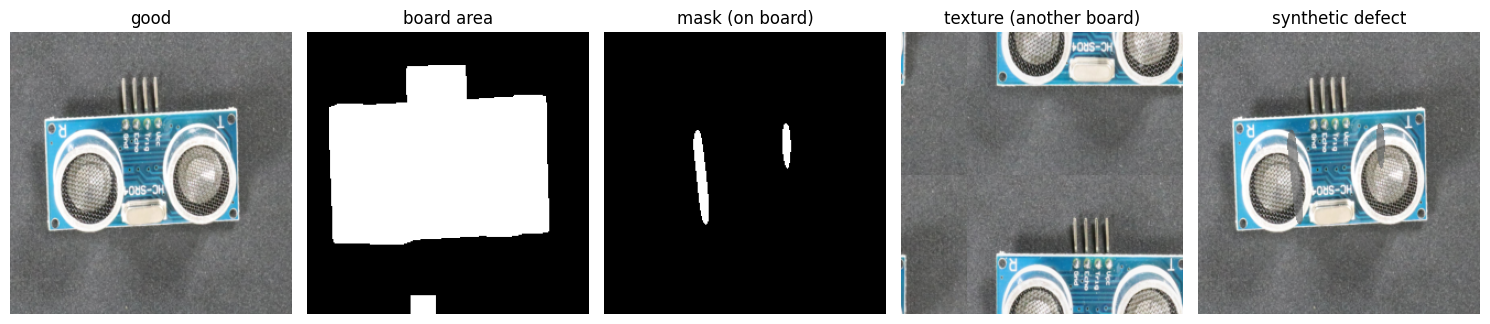

In [4]:
import torch.nn.functional as F

def blob_mask(size, max_frac=0.04):
    """平滑雜訊取最亮的一塊 → 不規則斑塊，約佔畫面 0.5%–max_frac。"""
    low = torch.rand(1, 1, random.choice([4, 8, 16]), random.choice([4, 8, 16]))
    smooth = F.interpolate(low, size=(size, size), mode="bicubic", align_corners=False)[0, 0]
    frac = random.uniform(0.005, max_frac)
    thr = smooth.flatten().kthvalue(int((1 - frac) * size * size)).values
    return (smooth > thr).float()                                   # [H, W]

def texture(size):
    """紋理：另一片良品，隨機旋轉 0/90/180/270°、平移、調亮暗 → 貼上去像「零件長錯地方」。"""
    y = X_good[random.randrange(len(X_good))]
    y = torch.rot90(y, random.randrange(4), (1, 2))
    y = torch.roll(y, (random.randrange(size), random.randrange(size)), (1, 2))
    return (y * random.uniform(0.6, 1.4) + random.uniform(-0.2, 0.2)).clamp(0, 1)          # [3, H, W]

def board_mask(x):
    """x: [3, H, W] → [H, W] 0／1：板子、白色探頭、針腳（彩度高或很亮），稍微往外擴一點；灰色桌面是 0。"""
    sat = x.max(0).values - x.min(0).values
    fg = ((sat > 0.15) | (x.mean(0) > 0.62)).float()
    k = 11 * x.shape[1] // 128 | 1                      # 擴張的大小跟著 SIZE 走（奇數）
    return F.max_pool2d(fg[None, None], k, 1, k // 2)[0, 0]

def synth_defect(x):
    """x: [3, H, W] 良品 → (合成瑕疵影像, 遮罩 [1, H, W])。一半的機率不加瑕疵（教模型也要說「沒有」）。"""
    if random.random() < 0.5:
        return x, torch.zeros(1, *x.shape[1:])
    m = blob_mask(x.shape[1]) * board_mask(x)       # 只留板子上的斑塊
    if m.sum() < 4:                                   # 斑塊剛好全落在桌面上：這張就當成沒有瑕疵
        return x, torch.zeros(1, *x.shape[1:])
    t = texture(x.shape[1])
    beta = random.uniform(0.0, 0.5)
    x_aug = x * (1 - m) + (beta * x + (1 - beta) * t) * m
    return x_aug.clamp(0, 1), m.unsqueeze(0)

import matplotlib.pyplot as plt
random.seed(1)
x0 = X_good[0]
m = blob_mask(SIZE) * board_mask(x0); t = texture(SIZE)
xs = (x0 * (1 - m) + (0.3 * x0 + 0.7 * t) * m).clamp(0, 1)
fig, ax = plt.subplots(1, 5, figsize=(15, 3.6))
for a, img, title in zip(ax, [x0.permute(1, 2, 0), board_mask(x0), m, t.permute(1, 2, 0), xs.permute(1, 2, 0)],
                         ["good", "board area", "mask (on board)", "texture (another board)", "synthetic defect"]):
    a.imshow(img, cmap="gray" if img.ndim == 2 else None); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.savefig("synth_strip.png", dpi=120); plt.show()

In [5]:
from torch.utils.data import Dataset, DataLoader

class DefectData(Dataset):
    """良品（當場合成瑕疵，每個 epoch 都不一樣）＋ 真實遮罩（重複 4 次，免得被幾百張良品淹沒）。"""
    def __init__(self, X, X_real, M_real, repeat=4):
        self.X, self.Xr, self.Mr, self.repeat = X, X_real, M_real, repeat
    def __len__(self):
        return len(self.X) + self.repeat * len(self.Xr)
    def __getitem__(self, i):
        if i >= len(self.X):                     # 真實不良品＋技術員的遮罩
            j = (i - len(self.X)) % len(self.Xr)
            x, m = self.Xr[j], self.Mr[j]
            if random.random() < 0.5:
                x, m = x.flip(-1), m.flip(-1)    # 左右翻轉：影像和遮罩要一起翻
            return x, m
        x = self.X[i]
        if random.random() < 0.5:
            x = x.flip(-2, -1)                   # 旋轉 180°：VisA PCB1 良品約八成倒著拍，兩種方向都要學（D2-1 的資料陷阱）
        return synth_defect(x) if USE_SYNTH else (x, torch.zeros(1, *x.shape[1:]))

train_ds = DefectData(X_good, X_lab, M_lab)          # 驗證集 X_val 不進訓練
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
xb, mb = next(iter(train_loader))
print("訓練資料", len(train_ds), "張／epoch（良品", len(X_good), "＋ 真實", len(X_lab), "× 4）；驗證", len(X_val), "張")
print("一個批次：x", tuple(xb.shape), "| 遮罩", tuple(mb.shape), "| 有瑕疵的張數", int((mb.flatten(1).sum(1) > 0).sum()))

訓練資料 1013 張／epoch（良品 853 ＋ 真實 40 × 4）；驗證 10 張
一個批次：x (16, 3, 256, 256) | 遮罩 (16, 1, 256, 256) | 有瑕疵的張數 11


**訓練之前先看資料**：模型真正吃進去的樣本（紅線＝遮罩的邊界，也就是「正確答案」）。
上排：良品＋合成瑕疵（或沒加瑕疵）；下排：技術員標的真實不良品。遮罩和瑕疵的位置對得上嗎？

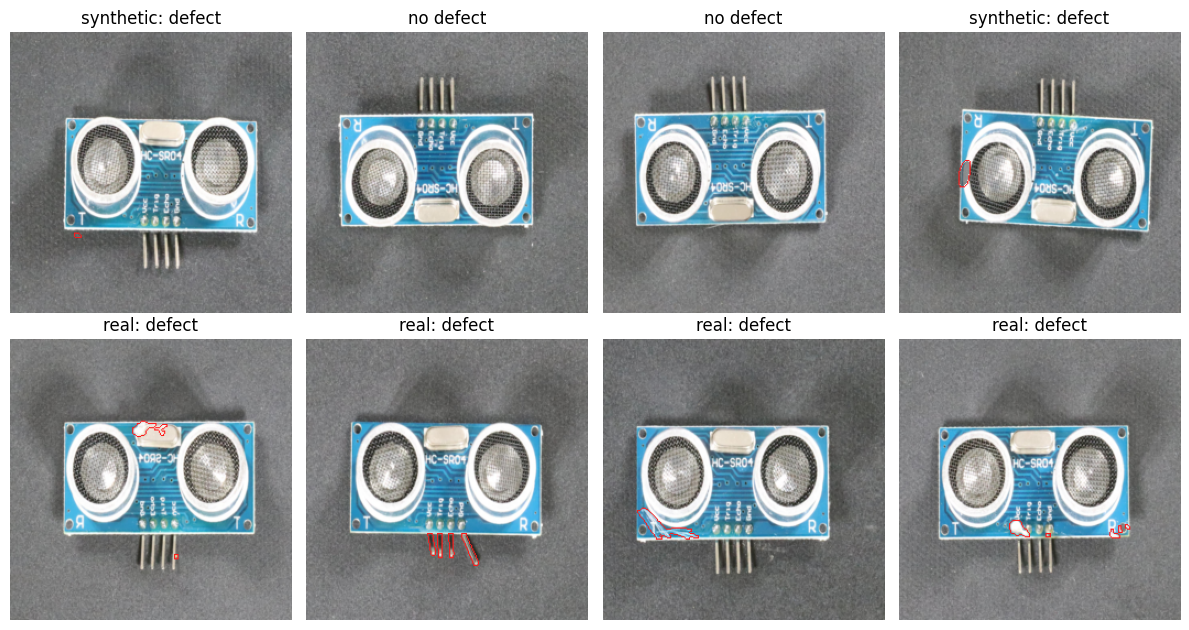

In [6]:
def edge(m):
    """0／1 遮罩 [H, W] → 只留邊界的 0／1 遮罩。"""
    m = m.bool()
    inner = m.clone()
    inner[1:-1, 1:-1] = m[1:-1, 1:-1] & m[:-2, 1:-1] & m[2:, 1:-1] & m[1:-1, :-2] & m[1:-1, 2:]
    return m & ~inner

random.seed(3)
show = [train_ds[i] for i in random.sample(range(len(X_good)), 4)] +        [train_ds[len(X_good) + i] for i in range(4)] if len(X_lab) else [train_ds[i] for i in range(8)]
fig, ax = plt.subplots(2, 4, figsize=(12, 6.4))
for k, (a, (x, m)) in enumerate(zip(ax.flat, show)):
    img = x.permute(1, 2, 0).numpy().copy()
    e = edge(F.max_pool2d(m, 3, 1, 1)[0]).numpy()     # 遮罩稍微加粗再取邊界，才看得到
    img[e] = [1.0, 0.1, 0.1]
    a.imshow(img); a.axis("off")
    a.set_title(("real: " if k >= 4 and len(X_lab) else "synthetic: " if m.sum() > 0 else "") + ("defect" if m.sum() > 0 else "no defect"))
plt.tight_layout(); plt.savefig("train_batch.png", dpi=110); plt.show()

## 3. U-Net（三層）
和 D2-1 的自編碼器一樣「往下壓、再往上還原」，差別是**跳接**（skip connection）：
往下每一層的輸出，直接**接（concatenate）**到往上同一層，細節不必擠過瓶頸。
**先別執行**：在投影片「練習：U-Net 每一層的 shape」寫下預測。

In [7]:
import torch.nn as nn

def block(cin, cout):     # 兩次 3×3 卷積，高寬不變
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, c=32):
        super().__init__()
        self.enc1, self.enc2, self.enc3 = block(3, c), block(c, 2 * c), block(2 * c, 4 * c)
        self.pool = nn.MaxPool2d(2)
        self.mid = block(4 * c, 8 * c)
        self.up3, self.dec3 = nn.ConvTranspose2d(8 * c, 4 * c, 2, stride=2), block(8 * c, 4 * c)
        self.up2, self.dec2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2), block(4 * c, 2 * c)
        self.up1, self.dec1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2), block(2 * c, c)
        self.head = nn.Conv2d(c, 1, 1)         # 每個像素一個 logit

    def forward(self, x, show=False):
        e1 = self.enc1(x)                      # 高寬不變
        e2 = self.enc2(self.pool(e1))          # 高寬 ÷2
        e3 = self.enc3(self.pool(e2))          # 高寬 ÷4
        b = self.mid(self.pool(e3))            # 瓶頸：高寬 ÷8
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        out = self.head(d1)
        if show:
            for name, t in [("x", x), ("e1", e1), ("e2", e2), ("e3", e3), ("b（瓶頸）", b),
                            ("cat(up3(b), e3)", torch.cat([self.up3(b), e3], 1)), ("d3", d3), ("d1", d1), ("out", out)]:
                print(f"{name:18s} {tuple(t.shape)}")
        return out

model = UNet().to(device)
with torch.no_grad():
    model(xb.to(device), show=True)
print("參數量", sum(p.numel() for p in model.parameters()))

x                  (16, 3, 256, 256)
e1                 (16, 32, 256, 256)
e2                 (16, 64, 128, 128)
e3                 (16, 128, 64, 64)
b（瓶頸）              (16, 256, 32, 32)
cat(up3(b), e3)    (16, 256, 64, 64)
d3                 (16, 128, 64, 64)
d1                 (16, 32, 256, 256)
out                (16, 1, 256, 256)
參數量 1928417


## 4. 訓練：BCE ＋ Dice
- **BCE**（逐像素）：每個像素是「瑕疵／背景」的二元分類（DL 課的二元交叉熵）
- **Dice**：瑕疵通常只佔不到 1%，全部猜「背景」BCE 就很低；Dice 只看「瑕疵那幾個像素有沒有對到」

`loss = BCE + (1 − Dice)`

**Dice 只算有瑕疵的那幾張**：一個批次裡很多張根本沒有瑕疵，如果那些圖也算 Dice，
「什麼都不畫」就拿到滿分 → 模型學會偷懶、什麼都不畫（第一版就是這樣失敗的）。沒有瑕疵的圖交給 BCE 管。

每個 epoch 用**驗證集**（技術員標的那 10 張）量 IoU，只存最好的那個檢查點：訓練中途分數會上下跳，最後一個不一定最好。

epoch  1  loss 1.5192  驗證 IoU 0.000  (38s)  ← 目前最好，存檔
epoch  2  loss 1.2620  驗證 IoU 0.000  (74s)
epoch  3  loss 1.1241  驗證 IoU 0.034  (111s)  ← 目前最好，存檔
epoch  4  loss 1.0190  驗證 IoU 0.004  (149s)
epoch  5  loss 0.9251  驗證 IoU 0.001  (188s)
epoch  6  loss 0.8492  驗證 IoU 0.000  (228s)
epoch  7  loss 0.7698  驗證 IoU 0.017  (267s)
epoch  8  loss 0.6991  驗證 IoU 0.017  (305s)
epoch  9  loss 0.6120  驗證 IoU 0.007  (345s)
epoch 10  loss 0.6063  驗證 IoU 0.054  (385s)  ← 目前最好，存檔
epoch 11  loss 0.5278  驗證 IoU 0.008  (424s)
epoch 12  loss 0.5138  驗證 IoU 0.019  (463s)
epoch 13  loss 0.5162  驗證 IoU 0.106  (503s)  ← 目前最好，存檔
epoch 14  loss 0.5095  驗證 IoU 0.127  (542s)  ← 目前最好，存檔
epoch 15  loss 0.4775  驗證 IoU 0.152  (581s)  ← 目前最好，存檔
epoch 16  loss 0.4408  驗證 IoU 0.069  (620s)
epoch 17  loss 0.4310  驗證 IoU 0.116  (659s)
epoch 18  loss 0.4314  驗證 IoU 0.155  (698s)  ← 目前最好，存檔
epoch 19  loss 0.4380  驗證 IoU 0.150  (737s)
epoch 20  loss 0.3810  驗證 IoU 0.103  (777s)
載回最好的 epoch：驗證 IoU 0.155
VRAM 峰值 3.41 GB


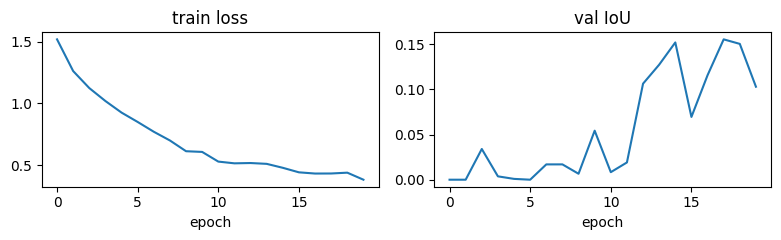

In [8]:
def dice_coef(prob, m, eps=1.0):
    """prob、m：[B, 1, H, W]；回傳每張的 Dice（平滑版，可微分）。"""
    inter = (prob * m).flatten(1).sum(1)
    return (2 * inter + eps) / (prob.flatten(1).sum(1) + m.flatten(1).sum(1) + eps)

bce = nn.BCEWithLogitsLoss()
def loss_fn(logits, m):
    has = m.flatten(1).sum(1) > 0                        # 這個批次裡有瑕疵的那幾張
    if not has.any():
        return bce(logits, m)
    return bce(logits, m) + (1 - dice_coef(torch.sigmoid(logits[has]), m[has]).mean())

@torch.no_grad()
def val_iou():
    """驗證集的平均 IoU（機率 > 0.5 算瑕疵）。"""
    model.eval()
    p = (torch.sigmoid(model(X_val.to(device))) > 0.5).float().cpu()
    inter = (p * M_val).flatten(1).sum(1); union = (p + M_val).clamp(max=1).flatten(1).sum(1)
    return (inter / union.clamp(min=1)).mean().item()

CKPT = "unet_pcb1_v2.pt"       # 講師提供的檢查點也用這個檔名；放好就會直接載入、跳過訓練（v2：合成＋真實遮罩）
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
history, val_hist = [], []
if os.path.exists(CKPT):
    ck = torch.load(CKPT, map_location=device)
    model.load_state_dict(ck["model"]); history, val_hist = ck.get("history", []), ck.get("val", [])
    print("載入檢查點", CKPT, "（已訓練", len(history), "epochs）")
else:
    t0, best = time.time(), -1.0
    for epoch in range(1, EPOCHS + 1):
        model.train(); total = 0.0
        for xb, mb in train_loader:
            xb, mb = xb.to(device), mb.to(device)
            logits = model(xb)
            loss = loss_fn(logits, mb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * len(xb)
        history.append(total / len(train_ds)); val_hist.append(val_iou())
        mark = ""
        if val_hist[-1] > best:                          # 只存驗證 IoU 最好的那一個
            best = val_hist[-1]; mark = "  ← 目前最好，存檔"
            torch.save({"model": model.state_dict(), "history": history, "val": val_hist}, CKPT)
        print(f"epoch {epoch:2d}  loss {history[-1]:.4f}  驗證 IoU {val_hist[-1]:.3f}  ({time.time()-t0:.0f}s){mark}")
    model.load_state_dict(torch.load(CKPT, map_location=device)["model"])
    print(f"載回最好的 epoch：驗證 IoU {best:.3f}")
    if device == "cuda":
        print(f"VRAM 峰值 {torch.cuda.max_memory_allocated()/1e9:.2f} GB")

fig, ax = plt.subplots(1, 2, figsize=(8, 2.5))
ax[0].plot(history); ax[0].set_xlabel("epoch"); ax[0].set_title("train loss")
ax[1].plot(val_hist); ax[1].set_xlabel("epoch"); ax[1].set_title("val IoU"); plt.tight_layout(); plt.show()

## 5. 在**真實遮罩**上評估
用**訓練時從沒看過**的真實不良品和人工標註的遮罩打分數（不是技術員標的那 50 張）。
- **IoU** ＝ 重疊 ÷ 聯集；**Dice** ＝ 2 × 重疊 ÷（預測面積＋真實面積）
- 機率 > 0.5 的像素算「瑕疵」

In [9]:
@torch.no_grad()
def predict(x):
    model.eval()
    return torch.sigmoid(model(x.to(device))).cpu()          # [B, 1, H, W]，0–1

def iou_dice(pred, m):
    """pred、m：0／1 遮罩 [B, 1, H, W] → 每張的 IoU 與 Dice。"""
    inter = (pred * m).flatten(1).sum(1)
    area_p, area_m = pred.flatten(1).sum(1), m.flatten(1).sum(1)
    union = area_p + area_m - inter
    iou = torch.where(union > 0, inter / union.clamp(min=1), torch.ones_like(inter))
    dice = torch.where(area_p + area_m > 0, 2 * inter / (area_p + area_m).clamp(min=1), torch.ones_like(inter))
    return iou, dice

P = torch.cat([predict(X_bad[i:i + 16]) for i in range(0, len(X_bad), 16)])
pred = (P > 0.5).float()
iou, dice = iou_dice(pred, M_bad)
print(f"測試用真實不良品 {len(X_bad)} 張（訓練沒看過）：平均 IoU {iou.mean():.3f}｜平均 Dice {dice.mean():.3f}")
print(f"IoU 中位數 {iou.median():.3f}；IoU = 0（完全沒對到）的張數 {(iou == 0).sum().item()}")

# 對照：合成瑕疵上的成績（通常好很多，見「風險」頁）
random.seed(123)
xs_, ms_ = zip(*[synth_defect(X_good[i % len(X_good)]) for i in range(64)])
xs_, ms_ = torch.stack(xs_), torch.stack(ms_)
has = ms_.flatten(1).sum(1) > 0
iou_s, dice_s = iou_dice((predict(xs_) > 0.5).float(), ms_)
print(f"合成瑕疵（有瑕疵的 {has.sum().item()} 張）：平均 IoU {iou_s[has].mean():.3f}｜平均 Dice {dice_s[has].mean():.3f}")

測試用真實不良品 50 張（訓練沒看過）：平均 IoU 0.304｜平均 Dice 0.411
IoU 中位數 0.292；IoU = 0（完全沒對到）的張數 11
合成瑕疵（有瑕疵的 23 張）：平均 IoU 0.468｜平均 Dice 0.590


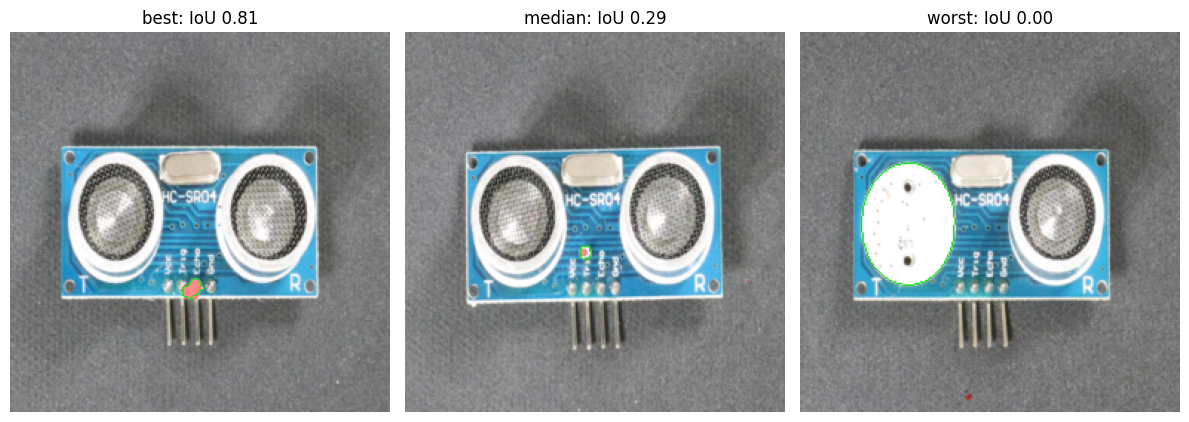

In [10]:
def overlay(x, pred, m=None):
    """紅色＝預測；綠色輪廓＝真實遮罩。"""
    img = x.permute(1, 2, 0).numpy().copy()
    p = pred[0].numpy() > 0
    img[p] = 0.5 * img[p] + 0.5 * np.array([1.0, 0.1, 0.1])
    if m is not None:
        mm = m[0].numpy() > 0
        edge = mm & ~np.pad(mm, 1)[2:, 1:-1] | mm & ~np.pad(mm, 1)[:-2, 1:-1] | mm & ~np.pad(mm, 1)[1:-1, 2:] | mm & ~np.pad(mm, 1)[1:-1, :-2]
        img[edge] = [0.1, 0.9, 0.1]
    return img

order = iou.argsort(descending=True)
pick = [order[0].item(), order[len(order) // 2].item(), order[-1].item()]      # 最好、中間、最差
fig, ax = plt.subplots(1, 3, figsize=(12, 4.2))
for a, i, tag in zip(ax, pick, ["best", "median", "worst"]):
    a.imshow(overlay(X_bad[i], pred[i], M_bad[i])); a.set_title(f"{tag}: IoU {iou[i]:.2f}"); a.axis("off")
plt.tight_layout(); plt.savefig("overlays.png", dpi=120); plt.show()

### 面積：像素 → mm²
維修站要的是 mm²，需要**校正值**：一個像素對應幾 mm。
PCB1 的板子是 HC-SR04 超音波模組，板子約 45 × 20 mm（常見規格，待確認）；
講師在原圖（1404 × 1070）上量到板子約 946 × 418 像素。縮放成 SIZE × SIZE 之後，水平和垂直的比例不一樣，要分開算。

In [11]:
BOARD_MM, BOARD_PX, ORIG = (45, 20), (946, 418), (1404, 1070)
mm_x = BOARD_MM[0] / BOARD_PX[0] * ORIG[0] / SIZE      # 縮放後，一個像素寬幾 mm
mm_y = BOARD_MM[1] / BOARD_PX[1] * ORIG[1] / SIZE      # 縮放後，一個像素高幾 mm
PX_MM2 = mm_x * mm_y
print(f"縮放後一個像素 ≈ {mm_x:.3f} × {mm_y:.3f} mm ＝ {PX_MM2:.4f} mm²")
area_pred = pred.flatten(1).sum(1) * PX_MM2
area_true = M_bad.flatten(1).sum(1) * PX_MM2
for i in pick:
    print(f"第 {i:3d} 張：預測 {area_pred[i]:6.2f} mm²｜真實 {area_true[i]:6.2f} mm²")
print(f"面積平均絕對誤差 {(area_pred - area_true).abs().mean():.2f} mm²")

縮放後一個像素 ≈ 0.261 × 0.200 mm ＝ 0.0522 mm²
第  24 張：預測   7.10 mm²｜真實   6.78 mm²
第  14 張：預測   1.10 mm²｜真實   3.29 mm²
第  32 張：預測   0.63 mm²｜真實 216.52 mm²
面積平均絕對誤差 19.84 mm²


## 6. Ship：Gradio 維修站工具

In [12]:
import gradio as gr

def locate(img):
    x = tf(img.convert("RGB"))
    p = (predict(x.unsqueeze(0))[0] > 0.5).float()
    area = p.sum().item() * PX_MM2
    out = (overlay(x, p) * 255).astype(np.uint8)
    return out, f"瑕疵面積約 {area:.2f} mm²（校正：板寬 45 mm）"

demo = gr.Interface(
    fn=locate,
    inputs=gr.Image(type="pil", label="上傳 PCB 影像"),
    outputs=[gr.Image(label="紅色＝預測的瑕疵"), gr.Textbox(label="面積")],
    title="曜嶼電子（虛構）維修站 · 瑕疵位置與面積",
    description="U-Net，良品＋合成瑕疵＋40 張真實遮罩訓練。資料：VisA PCB1（CC BY 4.0）。",
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cbdf303e231ddaefa9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
